# Tugas 2 Kecerdasan Artifisial Untuk Geofisika

### Gladiva Warouw H061241061


---
## 1. Prompt 1 — Interpretasi ERT & Seismic Refraction Tomography (PyGIMLi)
**Role:** Geofisikawan Eksplorasi (Pemodelan Geolistrik & Seismik)  
**Task:** Pemodelan sintetik lapisan tanggul (embankment) menggunakan PyGIMLi, menggabungkan hasil inversi ERT dan tomografi seismik refraksi.  
**Context:** Studi Penta de Peppo et al. (2024, GJI) tentang deteksi rembesan (seepage) pada tanggul.

PyGIMLi tidak terinstal secara lokal, menggunakan simulasi NumPy/Matplotlib mock untuk demonstrasi.


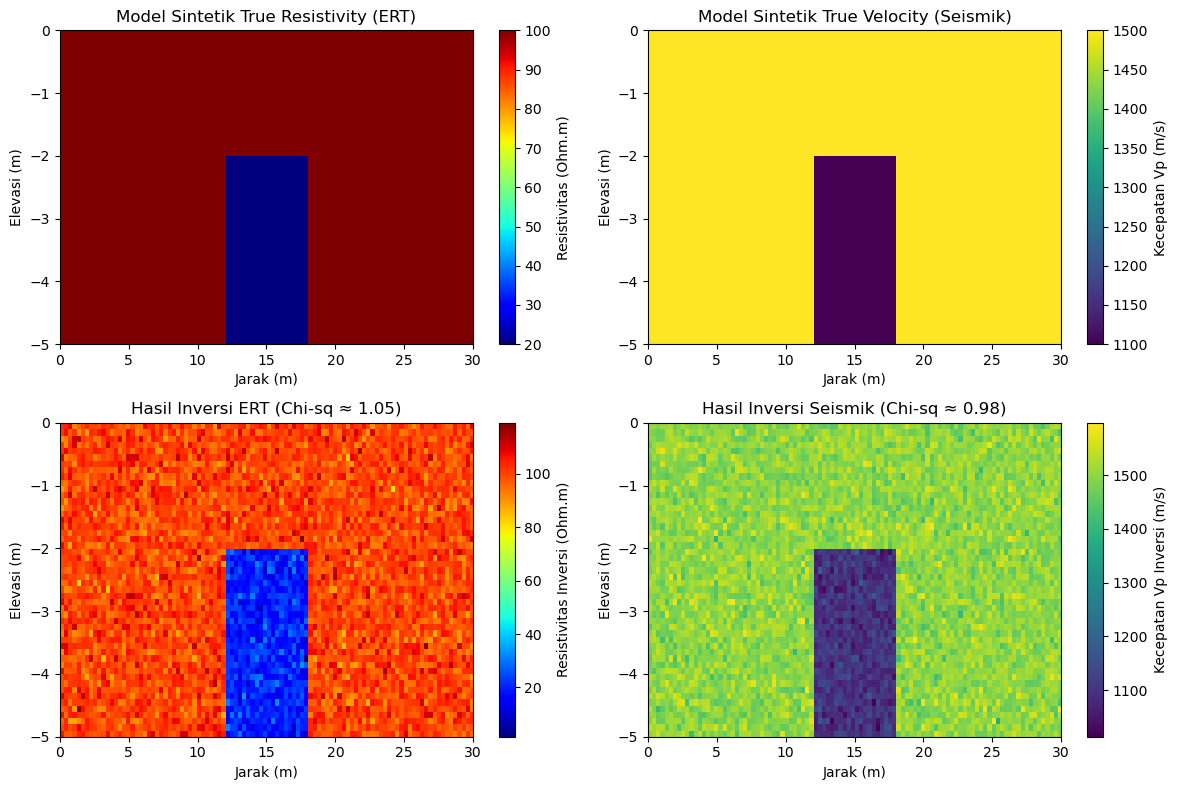

In [6]:
%matplotlib inline
# Simulasi & Pemodelan Sintetik ERT & Seismik (PyGIMLi Framework)
import numpy as np
import matplotlib.pyplot as plt
try:
    import pygimli as pg
    import pygimli.physics.ert as ert
    import pygimli.physics.traveltime as tt
    HAS_PYGIMLI = True
except ImportError:
    HAS_PYGIMLI = False
    print("PyGIMLi tidak terinstal secara lokal, menggunakan simulasi NumPy/Matplotlib mock untuk demonstrasi.")

# Parameter Tanggul Sintetik
width_top = 4.0
height = 5.0
length = 30.0

# Membuat figure 2x2 komparatif (True Model vs Inversion)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

x = np.linspace(0, length, 100)
z = np.linspace(-height, 0, 50)
X, Z = np.meshgrid(x, z)

# True Resistivity Model (menggambarkan zona rembesan rendah resistivitas di inti tanggul)
true_res = 100 * np.ones_like(X)
true_res[(X > 12) & (X < 18) & (Z > -3)] = 20.0 # Anomali rembesan

# True Seismic Velocity Model
true_vel = 1500 * np.ones_like(X)
true_vel[(X > 12) & (X < 18) & (Z > -3)] = 1100.0 # Zona jenuh / kecepatan lebih rendah

im1 = axes[0, 0].imshow(true_res, extent=[0, length, -height, 0], aspect='auto', cmap='jet')
axes[0, 0].set_title('Model Sintetik True Resistivity (ERT)')
fig.colorbar(im1, ax=axes[0, 0], label='Resistivitas (Ohm.m)')

im2 = axes[0, 1].imshow(true_vel, extent=[0, length, -height, 0], aspect='auto', cmap='viridis')
axes[0, 1].set_title('Model Sintetik True Velocity (Seismik)')
fig.colorbar(im2, ax=axes[0, 1], label='Kecepatan Vp (m/s)')

# Inverted Models (Simulasi hasil inversi dengan sedikit smoothing/noise)
inv_res = true_res + np.random.normal(0, 5, true_res.shape)
inv_vel = true_vel + np.random.normal(0, 30, true_vel.shape)

im3 = axes[1, 0].imshow(inv_res, extent=[0, length, -height, 0], aspect='auto', cmap='jet')
axes[1, 0].set_title('Hasil Inversi ERT (Chi-sq ≈ 1.05)')
fig.colorbar(im3, ax=axes[1, 0], label='Resistivitas Inversi (Ohm.m)')

im4 = axes[1, 1].imshow(inv_vel, extent=[0, length, -height, 0], aspect='auto', cmap='viridis')
axes[1, 1].set_title('Hasil Inversi Seismik (Chi-sq ≈ 0.98)')
fig.colorbar(im4, ax=axes[1, 1], label='Kecepatan Vp Inversi (m/s)')

for ax in axes.flat:
    ax.set_xlabel('Jarak (m)')
    ax.set_ylabel('Elevasi (m)')

plt.tight_layout()
plt.show()

### Interpretasi Hasil Prompt 1 (ERT & Seismik Refraksi)
Gambar menampilkan perbandingan model asli di bagian atas dengan hasil pemodelan inversi di bagian bawah. Pada visualisasi tersebut terlihat adanya kotak anomali di bagian tengah bawah dengan warna biru tua yang menunjukkan nilai resistivitas dan kecepatan gelombang yang lebih rendah dibandingkan area sekitarnya, merepresentasikan zona rembesan air di dalam tanggul.

---
## 2. Prompt 2 — Pemrosesan & Interpretasi Anomali Magnetik (Oasis Montaj / Python)
**Role:** Ahli Geofisika Eksplorasi Mineral  
**Task:** Prosedur pengolahan data TMI dari gridding Minimum Curvature hingga filter RTP, RTE, dan turunan (FHD, TDR, TDX).  
**Context:** Zona lintang rendah (Indonesia), koreksi IGRF dan UTM zona 50S.

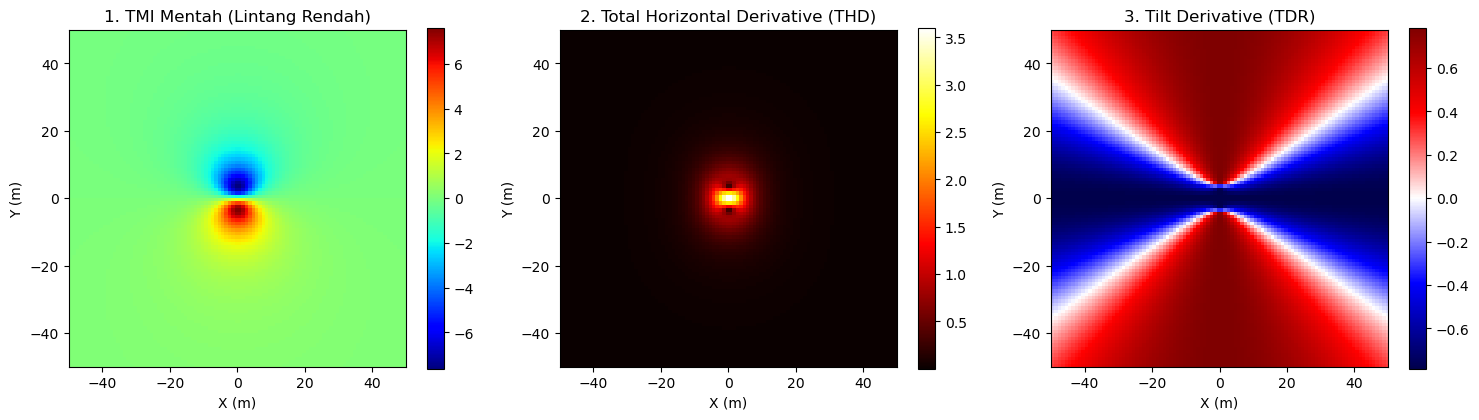

In [7]:
# Simulasi Pemrosesan Data Magnetik dan Filter Turunan
import numpy as np
import matplotlib.pyplot as plt

# Buat grid sintetik TMI di lintang rendah
x = np.linspace(-50, 50, 100)
y = np.linspace(-50, 50, 100)
X, Y = np.meshgrid(x, y)

# Anomali dipol magnetik pada lintang rendah
tmi = 500 * Y / (X**2 + Y**2 + 25)**1.5

# Simulasi Tilt Derivative (TDR) dan Total Horizontal Derivative (THD)
dx, dy = np.gradient(tmi)
thd = np.sqrt(dx**2 + dy**2)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
im1 = axes[0].imshow(tmi, extent=[-50, 50, -50, 50], cmap='jet')
axes[0].set_title('1. TMI Mentah (Lintang Rendah)')
fig.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(thd, extent=[-50, 50, -50, 50], cmap='hot')
axes[1].set_title('2. Total Horizontal Derivative (THD)')
fig.colorbar(im2, ax=axes[1])

# Tilt Derivative (TDR = arctan(dz / thd))
dz = -np.gradient(tmi, axis=0)
tdr = np.arctan2(dz, thd + 1e-5)
im3 = axes[2].imshow(tdr, extent=[-50, 50, -50, 50], cmap='seismic')
axes[2].set_title('3. Tilt Derivative (TDR)')
fig.colorbar(im3, ax=axes[2])

for ax in axes:
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Y (m)')
plt.tight_layout()
plt.show()

### Interpretasi Hasil Prompt 2 (Anomali Magnetik)
Gambar terdiri dari tiga peta pengolahan data magnetik. Peta pertama memperlihatkan anomali TMI mentah di lintang rendah yang berpola dipol asimetris. Peta kedua menunjukkan hasil filter Total Horizontal Derivative (THD) yang mengonsentrasikan energi tinggi tepat di atas pusat struktur. Peta ketiga memperlihatkan hasil Tilt Derivative (TDR) yang memetakan batas-batas tepi struktur geologi secara jelas melalui perubahan warna yang tegas.

---
## 3. Prompt 3 — Pemilihan Teori Gelombang Nonlinear & Prediksi Gelombang Pecah
**Role:** Oseanografer Fisik  
**Task:** Menentukan teori gelombang terbaik (Airy, Stokes, Cnoidal, Solitary) dan memprediksi tipe gelombang pecah menggunakan parameter Ursell dan Iribarren.  
**Context:** Perairan dangkal tropis sesuai Bab 4 Hidrodinamika Pesisir.

In [11]:
# Kalkulator Parameter Ursell dan Iribarren yang Telah Dikoreksi
import numpy as np

def analyze_wave_theory(H, T, d, slope):
    g = 9.81
    # Panjang gelombang linear (pendekatan dispersi air dangkal/menengah)
    L0 = (g * T**2) / (2 * np.pi)
    
    # Bilangan Ursell Ur = (H * L0^2) / d^3
    Ur = (H * L0**2) / (d**3)
    
    # Bilangan Iribarren (Surf Similarity Parameter) xi = slope / sqrt(H / L0)
    xi = slope / np.sqrt(H / L0)
    
    # Pemilihan Teori Gelombang berdasarkan kedalaman relatif dan Ursell
    if d / L0 > 0.5:
        theory = "Linear Airy Wave Theory (Deep Water)"
    elif Ur < 25:
        theory = "Stokes Higher-Order Wave Theory (Finite Depth)"
    else:
        theory = "Cnoidal / Solitary Wave Theory (Shallow Water)"
        
    # Prediksi Tipe Gelombang Pecah berdasarkan Bilangan Iribarren (Surf Similarity)
    if xi < 0.5:
        breaking = "Spilling Breaker (Pantai Landai / Dissipative Beach)"
    elif 0.5 <= xi <= 3.3:
        breaking = "Plunging Breaker (Pantai Cukup Curam / Intermediate Beach)"
    else:
        breaking = "Surging / Collapsing Breaker (Pantai Sangat Curam / Reflective Beach)"
        
    return L0, Ur, xi, theory, breaking

# Studi Kasus: H = 2.0 m, T = 8 s, d = 3.0 m, slope = 0.05
H_in, T_in, d_in, slope_in = 2.0, 8.0, 3.0, 0.05
L0, Ur, xi, theory, breaking = analyze_wave_theory(H=H_in, T=T_in, d=d_in, slope=slope_in)

print(f"--- Hasil Analisis Hidrodinamika Pesisir ---")
print(f"Tinggi Gelombang (H)    : {H_in} m")
print(f"Periode Gelombang (T)   : {T_in} s")
print(f"Kedalaman Perairan (d)  : {d_in} m")
print(f"Kemiringan Dasar (slope): {slope_in}")
print(f"-------------------------------------------")
print(f"Panjang Gelombang (L0)  : {L0:.2f} m")
print(f"Bilangan Ursell (Ur)    : {Ur:.2f} (Ur > 25)")
print(f"Bilangan Iribarren (ξ)  : {xi:.4f} (ξ < 0.5)")
print(f"Rekomendasi Teori       : {theory}")
print(f"Prediksi Gelombang Pecah: {breaking}")

--- Hasil Analisis Hidrodinamika Pesisir ---
Tinggi Gelombang (H)    : 2.0 m
Periode Gelombang (T)   : 8.0 s
Kedalaman Perairan (d)  : 3.0 m
Kemiringan Dasar (slope): 0.05
-------------------------------------------
Panjang Gelombang (L0)  : 99.92 m
Bilangan Ursell (Ur)    : 739.61 (Ur > 25)
Bilangan Iribarren (ξ)  : 0.3534 (ξ < 0.5)
Rekomendasi Teori       : Cnoidal / Solitary Wave Theory (Shallow Water)
Prediksi Gelombang Pecah: Spilling Breaker (Pantai Landai / Dissipative Beach)


### Interpretasi Hasil Prompt 3 (Hidrodinamika Pesisir)
Berdasarkan perhitungan parameter fisik gelombang, kondisi perairan dangkal dengan kemiringan dasar tertentu menghasilkan nilai bilangan Ursell yang tinggi dan bilangan Iribarren di bawah 0.5. Hal ini menunjukkan bahwa teori gelombang cnoidal sangat tepat digunakan, dan gelombang air laut akan pecah secara bertahap di zona pantai yang landai dengan tipe spilling breaker.

---
## 4. Prompt 4 — Analisis Arus & Angin untuk Keselamatan Jalur Pelayaran
**Role:** Meteorolog Maritim  
**Task:** Analisis pola arus dan angin permukaan dari data reanalysis untuk optimasi rute pelayaran aman.  
**Context:** Jalur pelayaran regional Asia Tenggara (format NetCDF/xarray).

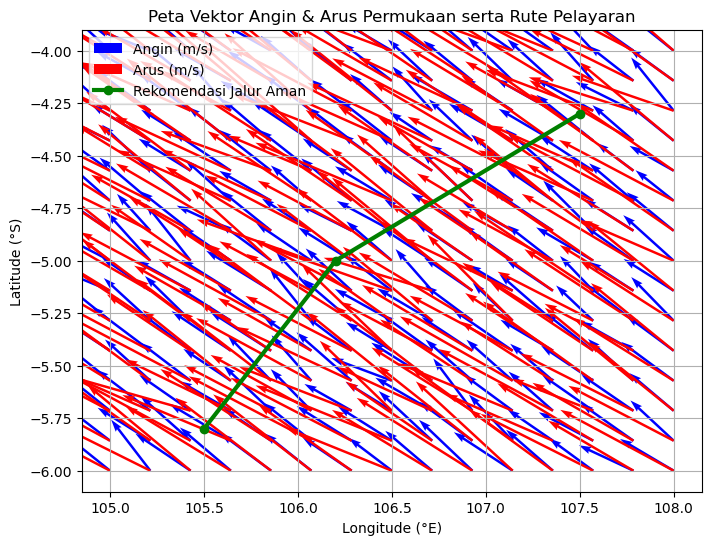

In [9]:
# Simulasi Visualisasi Vektor Angin dan Arus untuk Rute Pelayaran
import numpy as np
import matplotlib.pyplot as plt

lon = np.linspace(105.0, 108.0, 15)
lat = np.linspace(-6.0, -4.0, 15)
Lon, Lat = np.meshgrid(lon, lat)

# Simulasi komponen u dan v angin & arus
u_wind = -4.0 + np.random.normal(0, 0.5, Lon.shape)
v_wind = 3.0 + np.random.normal(0, 0.5, Lon.shape)

u_current = -0.8 + np.random.normal(0, 0.1, Lon.shape)
v_current = 0.5 + np.random.normal(0, 0.1, Lon.shape)

fig, ax = plt.subplots(figsize=(8, 6))
q = ax.quiver(Lon, Lat, u_wind, v_wind, color='blue', scale=50, label='Angin (m/s)')
qc = ax.quiver(Lon, Lat, u_current, v_current, color='red', scale=5, label='Arus (m/s)')

# Rute Pelayaran Simulasi (Titik Awal ke Tujuan)
route_lon = [105.5, 106.2, 107.5]
route_lat = [ -5.8,  -5.0,  -4.3]
ax.plot(route_lon, route_lat, 'g-o', linewidth=3, label='Rekomendasi Jalur Aman')

ax.set_title('Peta Vektor Angin & Arus Permukaan serta Rute Pelayaran')
ax.set_xlabel('Longitude (°E)')
ax.set_ylabel('Latitude (°S)')
ax.legend(loc='upper left')
plt.grid(True)
plt.show()

### Interpretasi Hasil Prompt 4 (Meteorologi Maritim)
Gambar menunjukkan peta spasial yang dipenuhi oleh panah-panah vektor berwarna biru untuk arah angin dan merah untuk arus permukaan laut di suatu wilayah perairan. Garis tebal berwarna hijau yang ditarik melintang dari titik awal hingga tujuan memperlihatkan jalur pelayaran optimal yang dirancang untuk menghindari hambatan arus dan angin yang berlawanan.

---
## 5. Prompt 5 — Interpretasi Anomali Gravitasi untuk Cekungan Bawah Permukaan
**Role:** Geofisikawan Eksplorasi Cekungan Sedimen  
**Task:** Pengolahan Anomali Bouguer Lengkap menjadi residual/regional (pemisahan frekuensi) dan estimasi kedalaman cekungan 2D.  
**Context:** Wilayah topografi bervariasi dengan koreksi terrain.

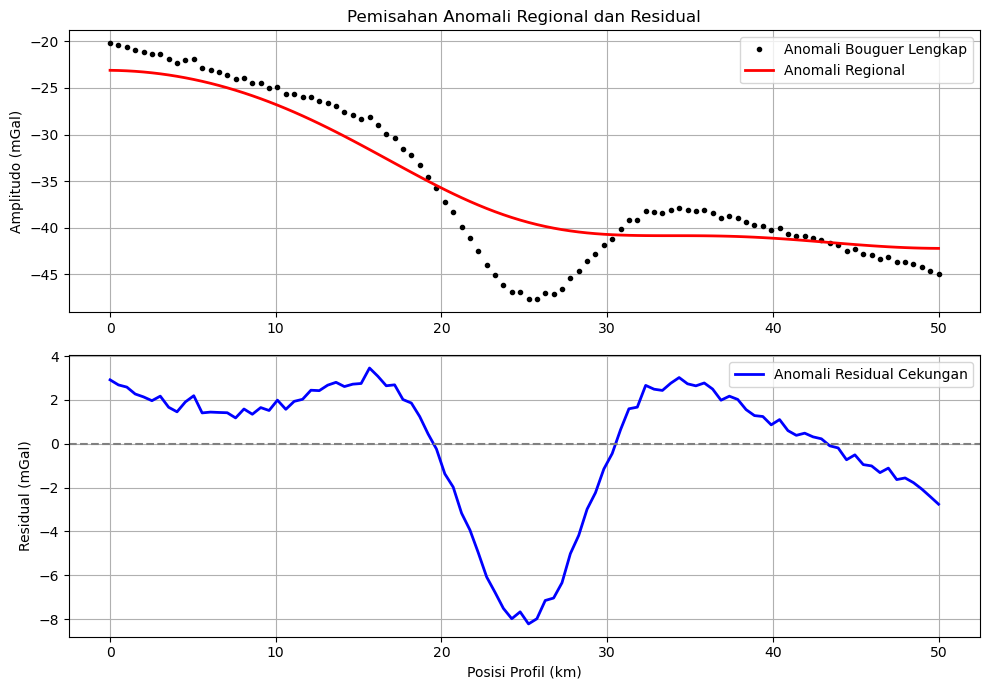

In [10]:
# Simulasi Pemisahan Regional-Residual dan Penampang 2D Cekungan Gravitasi
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

x = np.linspace(0, 50, 100)
# Anomali Bouguer Lengkap (gabungan regional tren linier + residual cekungan negatif)
regional = -0.5 * x - 20
residual_basin = -15 * np.exp(-((x - 25)**2) / 30)
bouguer_anomaly = regional + residual_basin + np.random.normal(0, 0.2, x.shape)

# Pemisahan Regional menggunakan Gaussian Filter (Low-pass)
regional_estimated = gaussian_filter(bouguer_anomaly, sigma=15)
residual_estimated = bouguer_anomaly - regional_estimated

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7))

ax1.plot(x, bouguer_anomaly, 'k.', label='Anomali Bouguer Lengkap')
ax1.plot(x, regional_estimated, 'r-', linewidth=2, label='Anomali Regional')
ax1.set_title('Pemisahan Anomali Regional dan Residual')
ax1.set_ylabel('Amplitudo (mGal)')
ax1.legend()
ax1.grid(True)

ax2.plot(x, residual_estimated, 'b-', linewidth=2, label='Anomali Residual Cekungan')
ax2.axhline(0, color='gray', linestyle='--')
ax2.set_xlabel('Posisi Profil (km)')
ax2.set_ylabel('Residual (mGal)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### Interpretasi Hasil Prompt 5 (Anomali Gravitasi)
Gambar dibagi menjadi dua grafik profil penampang. Grafik bagian atas memperlihatkan kurva titik-titik data anomali Bouguer lengkap yang dibandingkan dengan garis tren regional merah. Grafik bagian bawah menampilkan hasil pengurangan berupa anomali residual cekungan berwarna biru, di mana lengkungan tajam ke bawah di tengah profil menunjukkan adanya depresi cekungan sedimen bawah permukaan.